# Install dependencies

In [1]:
pip install pandas numpy matplotlib seaborn jupyter


   ---------------------------------------- 0/6 [webcolors]
   ------ --------------------------------- 1/6 [uri-template]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   ------------- -------------------------- 2/6 [lark]
   -------------------------- ------------- 4/6 [rfc3987-syntax]
   --------------------------------- ------ 5/6 [isoduration]
   --------------------------------- ------ 5/6 [isoduration]
   ---------------------------------------- 6/6 [isoduration]

Note: you may need to restart the kernel to use updated packages.


# Import libraries


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

os.makedirs("output", exist_ok=True)

print("Libraries imported successfully!")


Libraries imported successfully!


# Create sample raw dataset

In [2]:
data = {
    "Customer_ID": [
        101, 102, 103, 104, 105,
        106, 107, 108, 109, 110,
        101, 112, 113, 114, 115
    ],

    "Customer_Name": [
        "Arun", "Priya", "Kumar", "Divya",
        "Ravi", "Meena", "John", None,
        "Anitha", "Rahul", "Arun", "Karthik",
        "Sneha", "Vijay", "Sara"
    ],

    "Age": [
        25, 30, 28, np.nan, 35,
        40, 150, 27, 32, 29,
        25, 31, np.nan, 38, 26
    ],

    "Gender": [
        "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female",
        "Female", "Male", "Male", "Male",
        "Female", "Male", "Female"
    ],

    "Purchase_Amount": [
        2500, 4500, 3000, 5500, np.nan,
        8000, 12000, 3500, 4200, 6000,
        2500, 7000, 4000, 100000, 3200
    ],

    "Orders": [
        2, 4, 3, 5, 2,
        7, 8, 3, 4, 6,
        2, 5, 3, 9, 2
    ],

    "Purchase_Date": [
        "2026-01-05", "2026-01-10",
        "2026-01-15", "2026-02-02",
        "2026-02-10", "2026-02-15",
        "2026-03-01", "2026-03-05",
        "2026-03-10", "2026-03-15",
        "2026-01-05", "2026-04-01",
        "2026-04-05", "2026-04-10",
        "2026-04-15"
    ]
}

df = pd.DataFrame(data)

# Save raw dataset
df.to_csv("dataset.csv", index=False)

print("Raw dataset created!")
print(df)

Raw dataset created!
    Customer_ID Customer_Name    Age  Gender  Purchase_Amount  Orders  \
0           101          Arun   25.0    Male           2500.0       2   
1           102         Priya   30.0  Female           4500.0       4   
2           103         Kumar   28.0    Male           3000.0       3   
3           104         Divya    NaN  Female           5500.0       5   
4           105          Ravi   35.0    Male              NaN       2   
5           106         Meena   40.0  Female           8000.0       7   
6           107          John  150.0    Male          12000.0       8   
7           108          None   27.0  Female           3500.0       3   
8           109        Anitha   32.0  Female           4200.0       4   
9           110         Rahul   29.0    Male           6000.0       6   
10          101          Arun   25.0    Male           2500.0       2   
11          112       Karthik   31.0    Male           7000.0       5   
12          113         Sneha 

# Understand the dataset


# Display first five records


In [3]:
print(df.head())

   Customer_ID Customer_Name   Age  Gender  Purchase_Amount  Orders  \
0          101          Arun  25.0    Male           2500.0       2   
1          102         Priya  30.0  Female           4500.0       4   
2          103         Kumar  28.0    Male           3000.0       3   
3          104         Divya   NaN  Female           5500.0       5   
4          105          Ravi  35.0    Male              NaN       2   

  Purchase_Date  
0    2026-01-05  
1    2026-01-10  
2    2026-01-15  
3    2026-02-02  
4    2026-02-10  


# Dataset dimensions

In [5]:
print("\nDataset Shape:")
print(df.shape)


Dataset Shape:
(15, 7)


# Column information

In [6]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Customer_ID      15 non-null     int64  
 1   Customer_Name    14 non-null     object 
 2   Age              13 non-null     float64
 3   Gender           15 non-null     object 
 4   Purchase_Amount  14 non-null     float64
 5   Orders           15 non-null     int64  
 6   Purchase_Date    15 non-null     object 
dtypes: float64(2), int64(2), object(3)
memory usage: 972.0+ bytes


# Column names

In [7]:
print("\nColumns:")
print(df.columns)


Columns:
Index(['Customer_ID', 'Customer_Name', 'Age', 'Gender', 'Purchase_Amount',
       'Orders', 'Purchase_Date'],
      dtype='object')


# Statistical summary

In [8]:
print("\nStatistical Summary:")
print(df.describe())


Statistical Summary:
       Customer_ID         Age  Purchase_Amount     Orders
count    15.000000   13.000000        14.000000  15.000000
mean    107.333333   39.692308     11850.000000   4.333333
std       4.730851   33.482295     25502.963629   2.288689
min     101.000000   25.000000      2500.000000   2.000000
25%     103.500000   27.000000      3275.000000   2.500000
50%     107.000000   30.000000      4350.000000   4.000000
75%     111.000000   35.000000      6750.000000   5.500000
max     115.000000  150.000000    100000.000000   9.000000


# Handle missing values

# Check missing values

In [9]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Customer_ID        0
Customer_Name      1
Age                2
Gender             0
Purchase_Amount    1
Orders             0
Purchase_Date      0
dtype: int64


# Fill missing customer names

In [10]:
df["Customer_Name"] = df["Customer_Name"].fillna("Unknown")

# Fill missing age with median

In [11]:
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing purchase amount with median

In [14]:
df["Purchase_Amount"] = df["Purchase_Amount"].fillna(
    df["Purchase_Amount"].median()
)

In [15]:
print("\nMissing Values After Cleaning:")


Missing Values After Cleaning:


In [16]:
print(df.isnull().sum())

Customer_ID        0
Customer_Name      0
Age                0
Gender             0
Purchase_Amount    0
Orders             0
Purchase_Date      0
dtype: int64


# Remove duplicate records

In [17]:
print("Duplicates Before Cleaning:")
print(df.duplicated().sum())

Duplicates Before Cleaning:
1


# Remove duplicate records

In [18]:
df.drop_duplicates(inplace=True)

In [19]:
print("\nDuplicates After Cleaning:")
print(df.duplicated().sum())


Duplicates After Cleaning:
0


In [20]:
print("\nUpdated Dataset:")
print(df)


Updated Dataset:
    Customer_ID Customer_Name    Age  Gender  Purchase_Amount  Orders  \
0           101          Arun   25.0    Male           2500.0       2   
1           102         Priya   30.0  Female           4500.0       4   
2           103         Kumar   28.0    Male           3000.0       3   
3           104         Divya   30.0  Female           5500.0       5   
4           105          Ravi   35.0    Male           4350.0       2   
5           106         Meena   40.0  Female           8000.0       7   
6           107          John  150.0    Male          12000.0       8   
7           108       Unknown   27.0  Female           3500.0       3   
8           109        Anitha   32.0  Female           4200.0       4   
9           110         Rahul   29.0    Male           6000.0       6   
11          112       Karthik   31.0    Male           7000.0       5   
12          113         Sneha   30.0  Female           4000.0       3   
13          114         Vijay   3

# Fix incorrect data types

# Convert date column to datetime

In [21]:
df["Purchase_Date"] = pd.to_datetime(
    df["Purchase_Date"],
    errors="coerce"
)

# Convert numeric columns

In [22]:
df["Age"] = pd.to_numeric(
    df["Age"], errors="coerce"
)

In [23]:
df["Purchase_Amount"] = pd.to_numeric(
    df["Purchase_Amount"], errors="coerce"
)


In [24]:
df["Orders"] = pd.to_numeric(
    df["Orders"], errors="coerce"
)

In [25]:
print(df.dtypes)

Customer_ID                 int64
Customer_Name              object
Age                       float64
Gender                     object
Purchase_Amount           float64
Orders                      int64
Purchase_Date      datetime64[ns]
dtype: object


# Detect and treat outliers

# Use the Interquartile Range (IQR) method to identify unusually high or low purchase values.

# Detect outliers using IQR

In [26]:
Q1 = df["Purchase_Amount"].quantile(0.25)
Q3 = df["Purchase_Amount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: -1062.5
Upper Limit: 11437.5


# Identify outliers

In [27]:
outliers = df[
    (df["Purchase_Amount"] < lower_limit) |
    (df["Purchase_Amount"] > upper_limit)
]

print("\nDetected Outliers:")
print(outliers[["Customer_Name", "Purchase_Amount"]])


Detected Outliers:
   Customer_Name  Purchase_Amount
6           John          12000.0
13         Vijay         100000.0


# Treat outliers using capping

In [28]:
df["Purchase_Amount"] = df["Purchase_Amount"].clip(
    lower=lower_limit,
    upper=upper_limit
)

print("\nOutliers treated successfully!")


Outliers treated successfully!


# Exploratory Data Analysis (EDA)

# Total customers

In [29]:
total_customers = df["Customer_ID"].nunique()

# Total purchase amount

In [30]:
total_revenue = df["Purchase_Amount"].sum()

# Average purchase amount

In [31]:
average_purchase = df["Purchase_Amount"].mean()

# Total orders

In [32]:
total_orders = df["Orders"].sum()

In [33]:
print("CUSTOMER ANALYSIS REPORT")
print("------------------------")

print("Total Customers:", total_customers)
print("Total Revenue:", round(total_revenue, 2))
print("Average Purchase:", round(average_purchase, 2))
print("Total Orders:", total_orders)

CUSTOMER ANALYSIS REPORT
------------------------
Total Customers: 14
Total Revenue: 78625.0
Average Purchase: 5616.07
Total Orders: 63


# Summary statistics

In [34]:
summary = df[
    ["Age", "Purchase_Amount", "Orders"]
].agg([
    "mean",
    "median",
    "min",
    "max",
    "std"
])

print("Summary Statistics:")
print(summary)

Summary Statistics:
               Age  Purchase_Amount    Orders
mean     39.357143      5616.071429  4.500000
median   30.000000      4425.000000  4.000000
min      25.000000      2500.000000  2.000000
max     150.000000     11437.500000  9.000000
std      32.133393      2907.175426  2.278664


# Gender-wise spending

In [35]:
gender_analysis = df.groupby("Gender")[
    "Purchase_Amount"
].agg(["count", "mean", "sum"])

print("\nGender-wise Purchase Analysis:")
print(gender_analysis)


Gender-wise Purchase Analysis:
        count         mean      sum
Gender                             
Female      7  4700.000000  32900.0
Male        7  6532.142857  45725.0


# Correlation analysis

Correlation Matrix:
                      Age  Purchase_Amount    Orders
Age              1.000000         0.656808  0.521602
Purchase_Amount  0.656808         1.000000  0.946664
Orders           0.521602         0.946664  1.000000


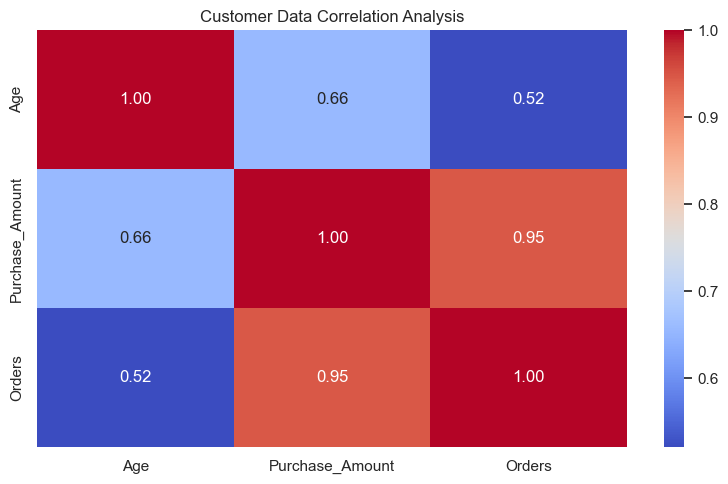

In [36]:
correlation = df[
    ["Age", "Purchase_Amount", "Orders"]
].corr()

print("Correlation Matrix:")
print(correlation)

# Heatmap
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Data Correlation Analysis")

plt.tight_layout()

plt.savefig("output/correlation_heatmap.png")

plt.show()

# Discover patterns and insights

# Highest spending customer

In [37]:
top_customer = df.loc[
    df["Purchase_Amount"].idxmax()
]

print("Top Spending Customer:")
print(top_customer["Customer_Name"])

print("Purchase Amount:")
print(top_customer["Purchase_Amount"])

Top Spending Customer:
John
Purchase Amount:
11437.5


# Highest number of orders

In [38]:
most_orders = df.loc[df["Orders"].idxmax()]

print("\nCustomer With Most Orders:")
print(most_orders["Customer_Name"])

print("Orders:", most_orders["Orders"])



Customer With Most Orders:
Vijay
Orders: 9


# Age group analysis

In [39]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 50, 100],
    labels=["Below 25", "26-35", "36-50", "Above 50"]
)

age_analysis = df.groupby(
    "Age_Group", observed=False
)["Purchase_Amount"].mean()

print("\nAge Group Purchase Analysis:")
print(age_analysis)


Age Group Purchase Analysis:
Age_Group
Below 25    2500.00
26-35       4525.00
36-50       9718.75
Above 50        NaN
Name: Purchase_Amount, dtype: float64


# Data visualization

# Purchase distribution

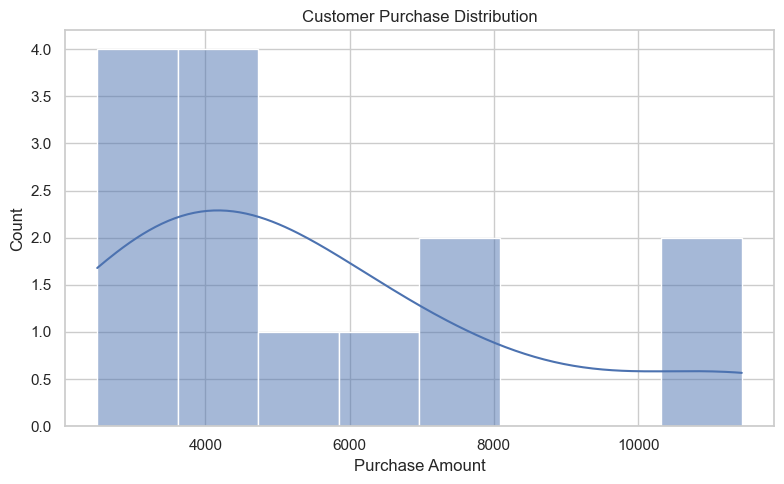

In [40]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["Purchase_Amount"],
    bins=8,
    kde=True
)

plt.title("Customer Purchase Distribution")
plt.xlabel("Purchase Amount")

plt.tight_layout()
plt.savefig("output/purchase_distribution.png")
plt.show()

# Customer spending analysis

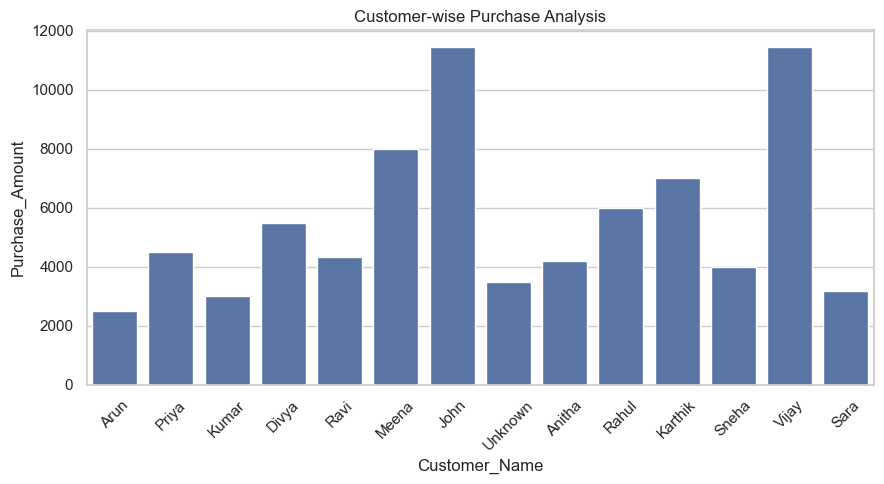

In [41]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Customer_Name",
    y="Purchase_Amount"
)

plt.title("Customer-wise Purchase Analysis")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("output/sales_analysis.png")
plt.show()

# Age versus purchase amount

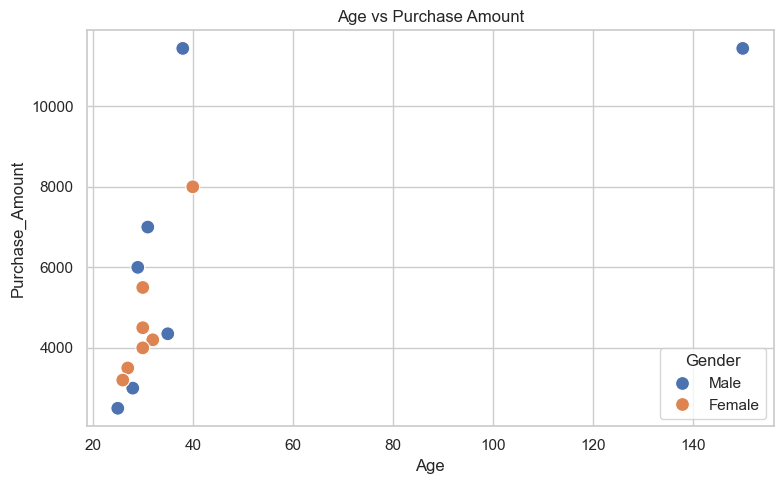

In [42]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Age",
    y="Purchase_Amount",
    hue="Gender",
    s=100
)

plt.title("Age vs Purchase Amount")

plt.tight_layout()
plt.show()

# Export cleaned dataset

In [43]:
df.to_csv(
    "output/cleaned_data.csv",
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!
